# PC01 — Xác định phạm vi khách hàng và xây dựng RFM

## Mục tiêu nghiệp vụ
Doanh nghiệp muốn nhận diện những kiểu khách khác nhau để ưu tiên nghiên cứu chăm sóc và duy trì mua hàng. Trước khi chia nhóm, cần thống nhất **đang nói về khách nào, đơn nào và giá trị nào**. Nếu một nơi đếm mọi đơn còn nơi khác cộng tiền delivered, nhóm thu được sẽ khó giải thích dù thuật toán vẫn chạy.

Notebook này tiếp nhận dữ liệu đã qua tiền xử lý chung của nhóm, xác minh phạm vi và tính lại RFM. Kết quả bàn giao là một dòng mỗi mã khách đủ điều kiện, có nguồn và tổng tiền đối soát được. **Chưa huấn luyện mô hình ở PC01.**

## Câu hỏi cần trả lời
1. Trạng thái trong dữ liệu là lịch sử sự kiện hay nhãn tại bản ghi nguồn?
2. Những khách nào đủ điều kiện, những khách nào cần giữ riêng?
3. R, F và M được tính qua những cấp dữ liệu nào?
4. Việc JOIN, lọc và tổng hợp có làm mất khách, mất đơn hoặc nhân tiền không?

## Quy ước và cách đọc
Mốc phân tích là **31/12/2022**, không phải ngày hiện tại. Đơn tính RFM mang trạng thái nguồn `delivered`. Đây là quy ước mô tả theo dữ liệu, chưa chứng nhận giao dịch đã quyết toán. Ngày đặt dùng cho Recency, không thay bằng ngày giao khi ngữ nghĩa chưa xác minh.

Mỗi mục đi theo **câu hỏi → định nghĩa/công thức → tính toán → bảng/hình → nhận xét → giới hạn**. Ví dụ học thuật có nhãn riêng và biến `toy_`; chúng không được ghép vào dữ liệu thật. Các nhận xét về kết quả dự án được sinh từ biến tính toán, không nhập số minh họa làm kết quả.


## Bản đồ ký hiệu và nguyên tắc đọc công thức

| Ký hiệu | Ý nghĩa trong notebook |
|---|---|
| c / i | Khách / chỉ số điểm dữ liệu; đọc định nghĩa tại từng công thức |
| o | Một order_id; không phải một dòng sản phẩm |
| E | Tập khách đủ điều kiện RFM delivered |
| T | Mốc31/12/2022 |
| n | Số khách của tập đang phân tích |
| k, Cj | Số cụm và tập khách của cụm j |
| R/F/M | Giá trị thô trên cùng tập đơn đủ điều kiện |
| x, z | Giá trị trước/sau biến đổi theo ngữ cảnh |
| μ, σ | Trung bình/tâm và độ lệch chuẩn, định nghĩa cụ thể cạnh công thức |

Một ký hiệu có thể dùng ở cấp khác trong một công thức khác; mỗi mục đều giải thích phạm vi và mẫu số. Đọc đơn vị, thời gian và trạng thái trước khi so số. Công thức minh họa và kết quả dự án được tách rõ. Các hàm Python giữ tên tiếng Anh để tái sử dụng; nội dung trình bày bằng tiếng Việt.


## Chuẩn bị môi trường và nguồn dữ liệu

Chạy với dữ liệu mô hình đã lưu trong data/model/phan_khuc/v1. Để huấn luyện lại từ PC03, đặt biến môi trường DATATHON_MODEL_RUN thành một tên lượt mới.

In [1]:
from pathlib import Path
import sys,json
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

from datathon.segmentation.study import Study,share_table,concentration,distribution
from datathon.segmentation.rfm_features import rfm
from datathon.segmentation.transformations import feature_matrix
from datathon.segmentation._shared import require,FEATURES,CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "v1")
study = Study(ROOT, "PC01")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)


Phần phân tích: PC01 | Thư mục kết quả: /workspace/scratch/1f9612b45e80/professional/DA_PC/reports/segmentation/professional_v1/PC01


## PC01.1 — Nguồn dữ liệu, cấp quan sát và hợp đồng sử dụng

**Câu hỏi:** dữ liệu đang ở cấp dòng hàng, đơn hay khách; tại sao phải phân biệt?

Một khách có nhiều đơn, một đơn có nhiều dòng hàng. Bảng `orders_common` có một dòng/đơn và đã tổng hợp tiền từ các bảng con theo quy tắc GD2. `order_items_common` giữ cấp dòng hàng. Bảng RFM cuối cùng phải có một dòng/khách.

| Cấp | Khóa sử dụng | Chỉ tiêu phù hợp |
|---|---|---|
| Dòng hàng | ID dòng nguồn | Quantity, giá trị dòng |
| Đơn | order_id duy nhất | Net đơn, số dòng, cờ theo đơn |
| Khách | customer_id duy nhất | R, F, M, tỷ lệ hành vi của khách |

Nếu JOIN Net đơn vào ba dòng hàng rồi cộng lại, một đơn bị tính tiền ba lần. Vì vậy, tính RFM từ bảng đơn và dùng bảng dòng cho những câu hỏi riêng về sản phẩm. Các phép nối kiểm `one_to_one` hoặc `many_to_one` theo cấp thực tế, không dựa vào việc JOIN chạy không báo lỗi.

**Cổng dữ liệu:** hash CSV phải khớp manifest; nguồn phải khớp hash đã dùng để tạo common; ID không được tự chuyển số hoặc strip để sửa mã. Tiền được đọc thành Decimal. Các kiểm tra này xác minh đầu vào kỹ thuật, không xác minh tiền tệ, quyết toán hoặc người thực đứng sau một mã khách.

**Liên hệ code:** `study.orders()` đọc và xác minh common. Bảng kiểu dữ liệu dưới đây là bằng chứng đã đọc đúng trước tổng hợp. Nếu cổng kiểm tra không đạt, cần đối soát nguồn thay vì bỏ kiểm tra để tiếp tục.


In [2]:
orders=study.orders()
source_schema=pd.DataFrame({'Cột':orders.columns,'Kiểu đọc':[str(t) for t in orders.dtypes]})
study.table('source_schema','Kiểu dữ liệu đầu vào common',source_schema)
require(orders.order_id.is_unique,'Đơn phải duy nhất')
study.note(f'Đọc {len(orders):,} đơn common. Tiền net_amount giữ Decimal; không suy float hoặc dùng payment để thay trạng thái.')

,Cột,Kiểu đọc
0,order_id,object
1,customer_id,object
2,order_status,object
3,order_date,datetime64[ns]
4,net_amount,object
5,order_before_signup_flag,object
6,delivered_missing_shipment_flag,object


Đọc 646,945 đơn common. Tiền net_amount giữ Decimal; không suy float hoặc dùng payment để thay trạng thái.

## PC01.2 — Trạng thái đơn và bằng chứng từ bảng liên quan

**Câu hỏi:** có nên coi payment hoặc ngày giao là bằng chứng để đổi trạng thái?

Orders hiện có một dòng cho mỗi order_id, không có thời gian cập nhật trạng thái. Vì vậy, chỉ quan sát được **nhãn trạng thái trong bộ dữ liệu**, không tái dựng được chuỗi created → paid → shipped → delivered hay thời điểm chuyển trạng thái.

Với trạng thái $s$, ký hiệu $O_s$ là số đơn mang nhãn đó. Vì mỗi đơn chỉ có một nhãn trong Orders:

$$\sum_s O_s = O.$$

$O$ là tổng số đơn. Ngược lại, tập khách $C_s$ có thể giao nhau: một khách có đơn hủy và đơn delivered khác nhau. Do đó không cộng $|C_s|$ để gọi là khách duy nhất; phải lấy hợp các tập.

Với bảng con $B$, độ phủ của trạng thái $s$ được định nghĩa:

$$Coverage_{s,B}=\frac{\#\{o:status(o)=s,\ o\text{ có bản ghi trong }B\}}{O_s}.$$

Đây là kiểm membership, không JOIN chi tiết bảng con để đếm. Một đơn có ba bản ghi returns vẫn chỉ là một đơn có returns trong bảng độ phủ.

**Quyết định:** giữ nguyên trạng thái nguồn. Shipped có delivery_date có thể liên quan ngày dự kiến hoặc trạng thái chưa cập nhật; payment dương ở cancelled/created chưa xác nhận đã thu. Delivered thiếu shipment là thiếu bằng chứng bổ trợ, chưa tự chứng minh nhãn sai. Phần độ nhạy sẽ đánh giá ảnh hưởng của các cách hiểu khác nhau, không thay nhãn ở bước này.


,Trạng thái,Số đơn,Có payments,Có shipments,Có returns,Có reviews
0,cancelled,59462,59462,0,0,0
1,created,7275,7275,0,0,0
2,delivered,516716,516716,516192,0,111369
3,paid,13577,13577,0,0,0
4,returned,36142,36142,36113,36062,0
5,shipped,13773,13773,13762,0,0


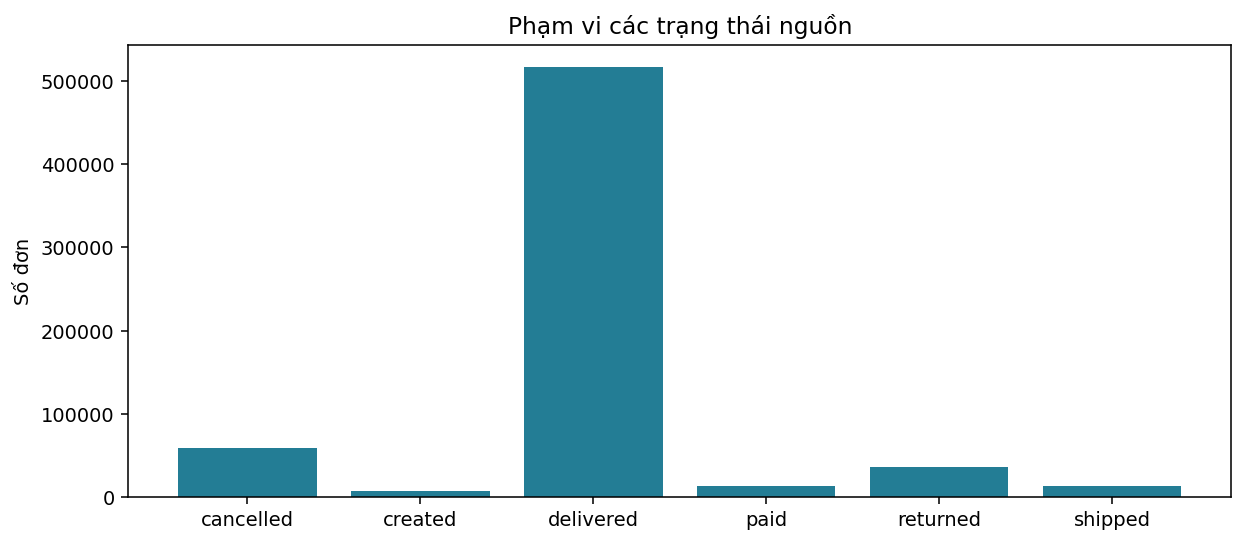

Có payment chỉ là có bản ghi; created/cancelled cũng có payment. Không đổi status từ bảng con. Returned thiếu returns và delivered thiếu shipment phải giữ cờ.

In [3]:
raw=ROOT/'data/raw'
children={name:set(pd.read_csv(raw/(name+'.csv'),dtype=str,usecols=['order_id']).order_id) for name in ['payments','shipments','returns','reviews']}
rows=[]
for status,g in orders.groupby('order_status'):
 row={'Trạng thái':status,'Số đơn':len(g)}
 for name,ids in children.items():row['Có '+name]=int(g.order_id.isin(ids).sum())
 rows.append(row)
coverage=study.table('status_coverage','Độ phủ trạng thái và bảng con',pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(9,4));ax.bar(coverage['Trạng thái'],coverage['Số đơn'],color='#237d95');ax.set(ylabel='Số đơn',title='Phạm vi các trạng thái nguồn');study.fig('status_counts','Số đơn theo trạng thái',fig)
study.note('Có payment chỉ là có bản ghi; created/cancelled cũng có payment. Không đổi status từ bảng con. Returned thiếu returns và delivered thiếu shipment phải giữ cờ.')

## PC01.3 — Tập khách phân tích và những khách ngoài phạm vi

**Câu hỏi:** mô hình đại diện cho toàn bộ khách hay chỉ khách có đơn đủ điều kiện?

Gọi $U$ là tập mã khách trong Customers, $H$ là tập có ít nhất một đơn và $E$ là tập có ít nhất một đơn delivered trong khoảng ngày đã chốt. Khi liên kết khóa hợp lệ, $E\subseteq H\subseteq U$.

Ba nhóm rời nhau để bàn giao là:

$$E,\qquad U\setminus H,\qquad H\setminus E.$$

Tổng số mã của ba nhóm phải bằng $|U|$. Tỷ lệ đủ điều kiện:

$$p_E=\frac{|E|}{|U|}.$$

Khách không có đơn delivered không có ngày mua delivered gần nhất để tính R. Gán R=0 sẽ làm họ giống khách mua ngay cuối kỳ; gán R rất lớn sẽ tự tạo nhóm “lâu không mua” bằng quy tắc kỹ thuật. Cả hai đều không phải quan sát dữ liệu.

**Cách xử lý:** giữ riêng mã và lý do ngoài phạm vi, không ép vào K-Means. Khách không đơn trong bộ nguồn chưa chắc chưa từng mua ngoài hệ thống; khách chỉ có đơn chưa delivered vẫn có thể có hoạt động đặt hàng. Bảng phạm vi dùng mẫu số toàn bộ Customers, trong khi các thống kê RFM sau đây dùng mẫu số $|E|$.

**Điểm bàn giao:** phân bố các cụm chỉ mô tả tập $E$, không được nhân tỷ trọng đó cho toàn bộ $U$ hoặc thay mẫu khách của NV02 bằng mẫu RFM.


,Lý do,Số khách,Tỷ trọng
0,eligible_delivered,85115,0.698064
1,no_order_records,31684,0.259854
2,orders_but_no_eligible_delivered,5131,0.042082


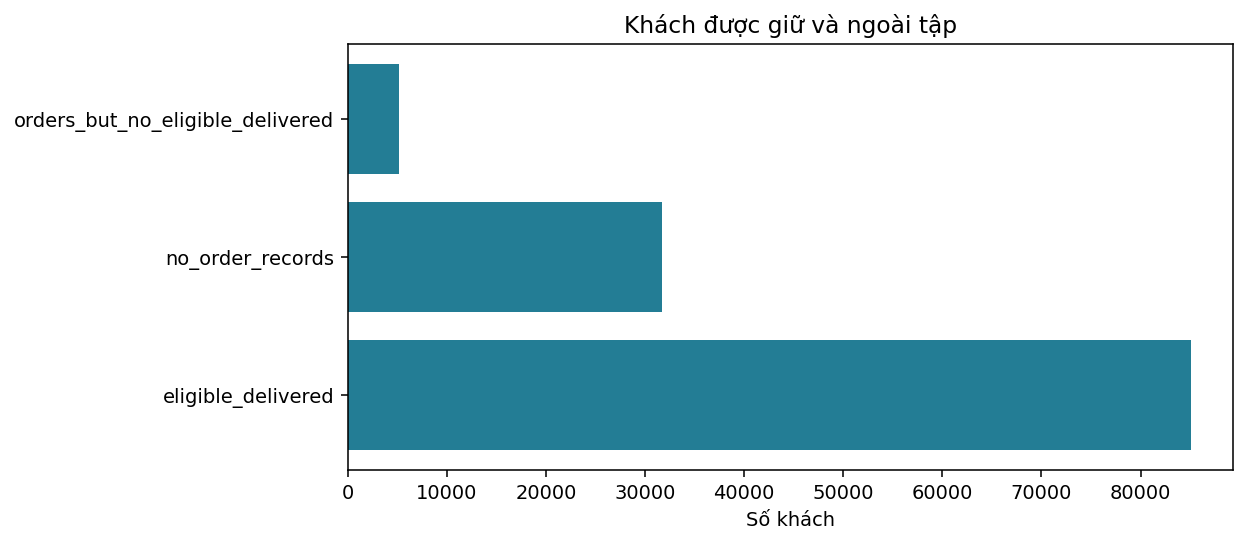

85,115/121,930 khách được phân cụm (69.81%); không suy rộng tỷ trọng cụm sang toàn bộ khách.

In [4]:
scope=study.scope.scope_reason.value_counts().rename_axis('Lý do').reset_index(name='Số khách')
scope['Tỷ trọng']=scope['Số khách']/scope['Số khách'].sum()
study.table('customer_scope','Phạm vi toàn bộ khách',scope)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(scope['Lý do'],scope['Số khách'],color='#237d95');ax.set(xlabel='Số khách',title='Khách được giữ và ngoài tập');study.fig('customer_scope','Phạm vi khách',fig)
require(scope['Số khách'].sum()==121930,'Mất khách trong bảng phạm vi')
study.note(f'{len(study.f):,}/{len(study.scope):,} khách được phân cụm ({len(study.f)/len(study.scope):.2%}); không suy rộng tỷ trọng cụm sang toàn bộ khách.')

## PC01.4 — Từ dòng hàng đến đơn và khách: công thức RFM

**Câu hỏi:** ba chỉ tiêu được hình thành như thế nào và có cùng phạm vi không?

Ký hiệu $T$ là 31/12/2022; $D_c$ là tập order_id của khách $c$ mang trạng thái delivered và có ngày đặt trong khoảng quan sát; $I_o$ là các dòng hàng thuộc đơn $o$.

| Ký hiệu | Định nghĩa | Đơn vị |
|---|---|---|
| $q_i$ | Số lượng của dòng $i$ | Đơn vị hàng |
| $p_i$ | Đơn giá nguồn của dòng $i$ | ĐVT nguồn/đơn vị hàng |
| $d_i$ | Tổng giảm giá của dòng $i$, trừ một lần | ĐVT nguồn |
| $t_o$ | Ngày đặt đơn $o$ | Ngày lịch |
| $D_c$ | Tập đơn đủ điều kiện của khách | Tập khóa, không phải số dòng hàng |

**Tiền ở cấp dòng và đơn:**

$$Net_o=\sum_{i\in I_o}(q_i p_i-d_i).$$

**Ba trục ở cấp khách:**

$$R_c=T-\max_{o\in D_c}t_o,$$

$$F_c=|D_c|,$$

$$M_c=\sum_{o\in D_c}Net_o.$$

R nhỏ nghĩa là lần đặt đơn thuộc tập delivered gần mốc chốt hơn; F là số đơn riêng biệt, không phải số sản phẩm; M là giá trị hàng hóa sau giảm, không phải lợi nhuận, quyết toán hay chi tiêu ròng sau hoàn trả. Cả ba dùng cùng $D_c$.

**Ví dụ giả lập, không phải số liệu dự án:** một đơn có hai dòng: $2\times100000-10000=190000$ và $1\times200000-20000=180000$, nên Net đơn là 370000. Khách có thêm một đơn Net=130000, vậy M=500000 và F=2. Nếu đơn cuối được đặt 25/12/2022 thì R=6 ngày. Có thêm một đơn cancelled không làm F/M delivered tăng, nhưng được ghi trong bảng hành vi bổ trợ.

**Tại sao không cộng payment?** Payment là một đại lượng đối chiếu khác; cộng cả Net và payment sẽ tính trùng một giá trị giao dịch. Không tự trừ refund khi thiếu quy tắc đối ứng và ngữ nghĩa tiền thực hiện.

**Kiểm chứng:** tổng F phải bằng số đơn chọn; tổng M phải bằng tổng Net đơn chọn; sau đó so từng khách với bảng tham chiếu. Khớp tổng là cần nhưng chưa đủ, vì hai sai lệch giữa khách có thể triệt tiêu nhau.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [5]:
# VÍ DỤ GIẢ LẬP: chỉ kiểm công thức; không đưa vào dữ liệu thật.
toy_items=pd.DataFrame({'Đơn':['VD01','VD01','VD02','VD03'],'Số lượng':[2,1,1,1],'Đơn giá':[Decimal('100000'),Decimal('200000'),Decimal('130000'),Decimal('2000000')],'Giảm dòng':[Decimal('10000'),Decimal('20000'),Decimal('0'),Decimal('0')]})
toy_items['Net dòng']=[Decimal(q)*p-d for q,p,d in zip(toy_items['Số lượng'],toy_items['Đơn giá'],toy_items['Giảm dòng'])]
toy_orders=pd.DataFrame({'order_id':['VD01','VD02','VD03'],'customer_id':['KH_VD']*3,'order_date':pd.to_datetime(['2022-12-12','2022-12-25','2022-12-30']),'Trạng thái':['delivered','delivered','cancelled']})
toy_orders=toy_orders.merge(toy_items.groupby('Đơn')['Net dòng'].sum().rename('net_amount'),left_on='order_id',right_index=True,validate='one_to_one')
toy_rfm=rfm(toy_orders.loc[toy_orders['Trạng thái'].eq('delivered')])
assert toy_rfm.iloc[0].Recency==6 and toy_rfm.iloc[0].Frequency==2 and toy_rfm.iloc[0].Monetary==Decimal('500000')
study.table('VD01_dong_hang','Ví dụ giả lập — từ dòng hàng đến đơn',toy_items)
study.table('VD01_rfm','Ví dụ giả lập — R=6, F=2, M=500000',toy_rfm[['customer_id','Recency','Frequency','Monetary']])
study.note('Ví dụ: đơn cancelled hai triệu không làm F/M delivered tăng. Mã KH_VD chỉ ở biến toy_, không ghép vào Study.f hoặc mô hình.')

,Đơn,Số lượng,Đơn giá,Giảm dòng,Net dòng
0,VD01,2,100000,10000,190000
1,VD01,1,200000,20000,180000
2,VD02,1,130000,0,130000
3,VD03,1,2000000,0,2000000


,Mã khách,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn)
0,KH_VD,6,2,500000


Ví dụ: đơn cancelled hai triệu không làm F/M delivered tăng. Mã KH_VD chỉ ở biến toy_, không ghép vào Study.f hoặc mô hình.

In [6]:
selected=orders.loc[orders.order_status.eq('delivered') & orders.order_date.le(CUTOFF)].copy()
recomputed=rfm(selected)
a=study.f.set_index('customer_id').sort_index();b=recomputed.set_index('customer_id').sort_index()
require(a.index.equals(b.index),'Tập khách thay đổi')
require(a.Monetary.eq(b.Monetary).all() and a.Frequency.eq(b.Frequency).all() and a.Recency.eq(b.Recency).all(),'RFM không khớp')
study.table('rfm_preview','Ví dụ RFM thực tế',recomputed[['customer_id','last_order_date','Recency','Frequency','Monetary']].head(10))
checks=pd.DataFrame({'Kiểm tra':['Đơn duy nhất','Khách duy nhất','Tổng F bằng số đơn','Tổng M khớp Decimal','Khớp RFM baseline'], 'Đạt':[selected.order_id.is_unique,recomputed.customer_id.is_unique,recomputed.Frequency.sum()==len(selected),sum(recomputed.Monetary,Decimal(0))==sum(selected.net_amount,Decimal(0)),True]})
study.table('rfm_reconciliation','Đối soát độc lập RFM từ common',checks)
study.note(f'Tổng Net={sum(recomputed.Monetary,Decimal(0)):,} ĐVT nguồn, trên {len(selected):,} đơn; đối chiếu từng khách khớp baseline. Không dùng tên tiền tệ chưa xác minh.')

,Mã khách,last_order_date,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn)
0,1,2020-02-24,1041,4,98782.44
1,10,2022-05-06,239,10,256542.98
2,10000,2017-11-28,1859,1,37244.0
3,100001,2018-04-15,1721,2,41916.38
4,100009,2020-04-10,995,3,135092.40
5,100010,2022-12-20,11,6,49678.38
6,100011,2017-11-16,1871,2,62296.42
7,100012,2022-12-24,7,4,106697.03
8,100015,2020-07-26,888,1,29079.82
9,100017,2020-07-27,887,1,25660.92


,Kiểm tra,Đạt
0,Đơn duy nhất,True
1,Khách duy nhất,True
2,Tổng F bằng số đơn,True
3,Tổng M khớp Decimal,True
4,Khớp RFM baseline,True


Tổng Net=12,518,175,957.20 ĐVT nguồn, trên 516,716 đơn; đối chiếu từng khách khớp baseline. Không dùng tên tiền tệ chưa xác minh.

## PC01.5 — Cờ bất thường và chính sách giữ dữ liệu

**Câu hỏi:** trường hợp nào được ghi nhận nhưng chưa có căn cứ loại?

Đơn trước signup_date có thể phản ánh ngữ nghĩa ngày đăng ký khác ngày bắt đầu mua; bộ dữ liệu chưa cho phép kết luận nguyên nhân. Đơn delivered thiếu shipment có thể thiếu bảng con, không đồng nghĩa giao thất bại. Vì vậy, giữ các trường hợp theo hợp đồng GD2 và báo độ phủ cờ.

Với cờ $A(o)$ theo đơn, tỷ lệ trong tập delivered là:

$$p_A=\frac{\sum_{o\in D}\mathbf{1}[A(o)=True]}{|D|}.$$

$D$ là toàn bộ đơn delivered được chọn. Nếu cờ có giá trị unknown, phải báo riêng unknown và mẫu số; không chuyển thành False. Các cờ có thể chồng lấn, nên không cộng số đếm các cờ thành “tổng lỗi”.

**Quyết định nghiệp vụ:** RFM chính tuân thủ trạng thái nguồn, không chọn lại tập đơn dựa trên kết quả cụm. Kịch bản bỏ delivered thiếu shipment ở PC05 là phép kiểm độ nhạy riêng. Điều này giúp phân biệt kết quả chính với ảnh hưởng của một điều kiện dữ liệu, thay vì âm thầm loại trường hợp khó.

**Đọc bảng:** số đơn mang cờ là số lần xuất hiện ở cấp đơn, chưa phải số khách bị ảnh hưởng. Một khách có nhiều đơn mang cờ vẫn chỉ là một mã khách trong hồ sơ cụm.


In [7]:
flags=[]
for col in ['order_before_signup_flag','delivered_missing_shipment_flag']:
 counts=selected[col].value_counts(dropna=False)
 for val,n in counts.items():flags.append({'Cờ':col,'Giá trị nguồn':str(val),'Số đơn delivered':int(n)})
study.table('retained_flags','Các cờ được giữ trong tập RFM',pd.DataFrame(flags))
study.note('Không dùng signup để sửa tuổi khách hoặc loại đơn. Đơn delivered thiếu shipment vẫn tham gia baseline; PC05 kiểm độ nhạy riêng. Hai cờ có thể chồng lấn, không cộng thành tổng lỗi.')

,Cờ,Giá trị nguồn,Số đơn delivered
0,order_before_signup_flag,True,382623
1,order_before_signup_flag,False,134093
2,delivered_missing_shipment_flag,False,516192
3,delivered_missing_shipment_flag,True,524


Không dùng signup để sửa tuổi khách hoặc loại đơn. Đơn delivered thiếu shipment vẫn tham gia baseline; PC05 kiểm độ nhạy riêng. Hai cờ có thể chồng lấn, không cộng thành tổng lỗi.

## PC01.6 — Thời gian, ý nghĩa phạm vi và điều kiện bàn giao

Ngày đặt, ngày giao, ngày cập nhật trạng thái và thời điểm trích xuất là bốn khái niệm khác nhau. Bộ nguồn có ngày đặt và một số ngày giao, nhưng chưa có nhật ký chuyển trạng thái hay thời điểm trạng thái sẵn có.

Vì vậy, mốc $T=31/12/2022$ là mốc quy ước để tính khoảng cách ngày, không chứng minh rằng toàn bộ thông tin trạng thái đã được biết tại chính ngày đó. Nghiên cứu hiện tại là mô tả bộ dữ liệu; không dùng kết quả này làm backtest as-of lịch sử hoặc khẳng định khách đã được nhận diện đúng tại một mốc quá khứ.

**Điều kiện bàn giao sang PC02:** tập khách/đơn rõ ràng, ID duy nhất ở cấp cần thiết, RFM không thiếu, tổng số đơn và tiền khớp, các trường hợp ngoài phạm vi có lý do. Những kiểm tra này là cổng kỹ thuật. Xác nhận tiền thực thu, nghĩa ngày giao và nguyên nhân bất thường vẫn cần tài liệu nghiệp vụ ngoài CSV.

**Kết luận cần nhớ:** RFM chỉ có ý nghĩa khi công thức và tập đơn đi cùng nhau. Một bộ RFM mọi trạng thái không sai về phép đếm nhưng trả lời câu hỏi khác, không được gọi tên như cùng một kết quả với RFM delivered.


In [8]:
definitions=pd.DataFrame([
{'Khái niệm':'order_date','Cách dùng':'Ngày đặt ghi nhận; dùng tính R','Không được suy':'Ngày giao hoặc ngày chuyển status'},
{'Khái niệm':'delivery_date','Cách dùng':'Bằng chứng bổ trợ, giả định độ nhạy','Không được suy':'Tự xác nhận shipped đã giao'},
{'Khái niệm':'31/12/2022','Cách dùng':'Mốc tham chiếu phân tích','Không được suy':'Ngày trích xuất/status sẵn có'},
{'Khái niệm':'delivered','Cách dùng':'Nhãn phạm vi theo nguồn','Không được suy':'Quyết toán xong, không bao giờ trả'}])
study.table('time_semantics','Quy ước và giới hạn thời gian',definitions)
study.note('Bàn giao PC02: cùng 85.115 khách, R/F/M liên tục, ngoài tập giữ riêng. Nếu thay định nghĩa phải ghi lại và tính lại, không sửa nhãn để hợp kết luận.')

,Khái niệm,Cách dùng,Không được suy
0,order_date,Ngày đặt ghi nhận; dùng tính R,Ngày giao hoặc ngày chuyển status
1,delivery_date,"Bằng chứng bổ trợ, giả định độ nhạy",Tự xác nhận shipped đã giao
2,31/12/2022,Mốc tham chiếu phân tích,Ngày trích xuất/status sẵn có
3,delivered,Nhãn phạm vi theo nguồn,"Quyết toán xong, không bao giờ trả"


Bàn giao PC02: cùng 85.115 khách, R/F/M liên tục, ngoài tập giữ riêng. Nếu thay định nghĩa phải ghi lại và tính lại, không sửa nhãn để hợp kết luận.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [9]:
study.note("### Kết luận nghiệp vụ PC01 và điều kiện chuyển bước")
study.note(f'Tập RFM gồm {len(study.f):,} mã khách đủ điều kiện trong {len(study.scope):,} mã nguồn. Việc bỏ khách ngoài phạm vi khỏi mô hình là do không có RFM delivered có ý nghĩa, không phải đánh giá họ không có giá trị. RFM được tính lại và so từng khách; bước tiếp theo nghiên cứu phân bố và cách đo khoảng cách, chưa vội chọn thuật toán.')

### Kết luận nghiệp vụ PC01 và điều kiện chuyển bước

Tập RFM gồm 85,115 mã khách đủ điều kiện trong 121,930 mã nguồn. Việc bỏ khách ngoài phạm vi khỏi mô hình là do không có RFM delivered có ý nghĩa, không phải đánh giá họ không có giá trị. RFM được tính lại và so từng khách; bước tiếp theo nghiên cứu phân bố và cách đo khoảng cách, chưa vội chọn thuật toán.

## Kiểm chứng và lưu sản phẩm phân tích

Đối chiếu hash nguồn, lưu bảng/hình và manifest. Công thức, ví dụ, kết quả và diễn giải đều nằm trong notebook; báo cáo HTML được xuất từ chính nội dung này.

In [10]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC01', 'state': 'completed', 'baseline': 'v1', 'model_run': 'v1', 'tables': 9, 'figures': 2, 'commentary_blocks': 9, 'raw_unchanged': True, 'baseline_manifest_sha256': '95948f0feb349f3091a85baa3a31a557ae652fa403e35d1be425a915294c3fef'}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
